# BNDES non-automatic operations → adaptation action bank (br-bndes-operacoes-financiamento, 2026-09-01)

Maps each distinct project description in the cleaned subcredit table to the ICB × OEF adaptation action bank (V13, 37 actions), with a match type. Links, never splits: contract amounts stay at contract level and are not divided across actions.
Inputs: `data/br_bndes_operacoes_financiamento_subcredits.csv.gz` (from `extract_clean.ipynb`), the crosswalk `data/br_bndes_operacoes_financiamento_to_adaptation_actions.csv`, and the action bank export in `sample/` (local-only; see README).
Need: `dataset-discovery/needs/2026-09-br-finance-pathways-review`. Restart-and-run-all must pass before commit.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SUBCREDITS_PATH = "data/br_bndes_operacoes_financiamento_subcredits.csv.gz"
CROSSWALK_PATH = "data/br_bndes_operacoes_financiamento_to_adaptation_actions.csv"
ACTION_BANK_PATH = "sample/adaptation_action_bank_icb_oef_v13.csv"   # ICB x OEF V13 "Final Action Bank" sheet, exported to CSV
RECENT_FROM_YEAR = 2015
MATCH_TYPES = ["direct", "component", "enabling", "related", "none"]
MATCH_RANK = {m: i for i, m in enumerate(MATCH_TYPES)}

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True})
MATCH_COLORS = {"direct": "#1f5f8b", "component": "#4f8fbf", "enabling": "#8cb8d9", "related": "#c8702a"}
print({p: os.path.exists(p) for p in [SUBCREDITS_PATH, CROSSWALK_PATH, ACTION_BANK_PATH]})

{'data/br_bndes_operacoes_financiamento_subcredits.csv.gz': True, 'data/br_bndes_operacoes_financiamento_to_adaptation_actions.csv': True, 'sample/adaptation_action_bank_icb_oef_v13.csv': True}


## 1. Load inputs

The action bank export has a two-line title block before the header, so the header is the second CSV record. Only ID, name and description are used.

In [2]:
subcredits = pd.read_csv(SUBCREDITS_PATH, dtype=str, keep_default_na=False)
crosswalk = pd.read_csv(CROSSWALK_PATH, dtype=str, keep_default_na=False)
action_bank = pd.read_csv(ACTION_BANK_PATH, header=1, dtype=str, keep_default_na=False)[["ID", "Action", "Description"]]
action_bank = action_bank.rename(columns={"ID": "action_id", "Action": "action_name", "Description": "action_description"})
print("subcredits:", subcredits.shape, "| crosswalk rows:", len(crosswalk), "| actions:", len(action_bank))
crosswalk.head(3)

subcredits: (23815, 59) | crosswalk rows: 6640 | actions: 37


,src_description_pt,src_description_en,action_id,action_name,match_type,mapping_confidence,is_weak_signal,adjudication_status,rationale
0,"""APOIO FINANCEIRO A REALIZACAO DE ACOES INTEGRANTES DO PLANOGENERICO DE INVESTIMENTOS ...",Financial support for carrying out actions under the general investment plan called th...,,,none,none,False,not required,No adaptation-related term in the description (keyword screen); not individually revie...
1,"""APOIO FINANCEIRO A REALIZACAO DE ACOES INTEGRANTES DO PLANOGENERICO DE INVESTIMENTOS ...",Financial support for carrying out actions under the general investment plan called th...,,,none,none,False,not required,No adaptation-related term in the description (keyword screen); not individually revie...
2,"""APRIMORAMENTO DA ESTRUTURA PRODUTIVA DA POSTULANTE, ATRAVES DA REALIZACAO DE OBRAS CI...","Improvement of the applicant's production structure, through civil works; acquisition ...",,,none,none,False,not required,No adaptation-related term in the description (keyword screen); not individually revie...


## 2. Validate the crosswalk — nothing downstream runs if these fail

Every distinct description in the subcredit table appears (mapped or `none`); every target resolves to the action bank with the same name; no duplicate pairs; `none` rows carry no target; medium rows and only medium rows await adjudication.

In [3]:
descriptions = set(subcredits["project_description_pt"])
assert set(crosswalk["src_description_pt"]) == descriptions, "crosswalk and subcredit descriptions differ; re-run the mapping for new descriptions"
assert not crosswalk.duplicated(["src_description_pt", "action_id"]).any()
assert set(crosswalk["match_type"]) <= set(MATCH_TYPES)
assert set(crosswalk["mapping_confidence"]) <= {"high", "medium", "none"}
is_none = crosswalk["match_type"].eq("none")
assert (is_none == crosswalk["mapping_confidence"].eq("none")).all()
assert crosswalk.loc[is_none, ["action_id", "action_name"]].eq("").all().all()
linked = crosswalk[~is_none]
names = action_bank.set_index("action_id")["action_name"]
assert linked["action_id"].isin(names.index).all(), "unknown action id"
assert (linked["action_name"] == linked["action_id"].map(names)).all(), "action name drifted from the action bank"
assert not (crosswalk.groupby("src_description_pt")["match_type"].apply(lambda s: s.eq("none").any() and s.ne("none").any())).any()
assert (crosswalk["adjudication_status"].eq("pending") == crosswalk["mapping_confidence"].eq("medium")).all()
assert crosswalk["rationale"].str.strip().ne("").all()
print("CROSSWALK VALID")
pd.crosstab(crosswalk["match_type"], crosswalk["mapping_confidence"])

CROSSWALK VALID


mapping_confidence,high,medium,none
match_type,,,
component,12,110,0
direct,80,26,0
enabling,5,15,0
none,0,0,6191
related,0,201,0


## 3. Contract-level evidence (in memory)

Subcredits join to the crosswalk on the Portuguese description. A contract links to an action if any of its descriptions does; the strongest match type wins. Contract totals are carried whole for context and are never divided among actions.

In [4]:
subcredits["contracted_amount_brl"] = subcredits["contracted_amount_brl"].astype(float)
subcredits["contract_year"] = subcredits["contract_year"].astype(int)
contract_attrs = subcredits.groupby("contract_number").agg(
    contract_year=("contract_year", "min"), client_name=("client_name", "first"), client_nature=("client_nature", "first"),
    state_code=("state_code", "first"), financing_instrument=("financing_instrument", lambda s: " | ".join(sorted(set(s)))),
    contract_total_brl=("contracted_amount_brl", "sum"))
contract_links = (subcredits[["contract_number", "project_description_pt"]].drop_duplicates()
    .merge(linked, left_on="project_description_pt", right_on="src_description_pt")
    .assign(rank=lambda d: d["match_type"].map(MATCH_RANK), conf_rank=lambda d: d["mapping_confidence"].map({"high": 0, "medium": 1}))
    .sort_values(["rank", "conf_rank"]).drop_duplicates(["contract_number", "action_id"])
    [["contract_number", "action_id", "action_name", "match_type", "mapping_confidence", "is_weak_signal"]]
    .join(contract_attrs, on="contract_number"))
contract_links["is_public_client"] = contract_links["client_nature"].str.startswith(("Direct public", "Public"))
print("contracts linked to ≥1 action:", contract_links["contract_number"].nunique(), "of", subcredits["contract_number"].nunique(),
      "| contract–action links:", len(contract_links))
contract_links.head()

contracts linked to ≥1 action: 450 of 8388 | contract–action links: 500


,contract_number,action_id,action_name,match_type,mapping_confidence,is_weak_signal,contract_year,client_name,client_nature,state_code,financing_instrument,contract_total_brl,is_public_client
46,6202021,ipcc_0101,Improve climate-resilient water and sanitation infrastructure,direct,high,False,2006,ESTADO DO CEARA (07954480),Direct public administration - state government,CE,Environment,71818138.0,True
78,6203391,icare_0170,"Build safe housing and implement urban rehabilitation, relocation and resettlement for...",direct,high,False,2007,MUNICIPIO DE BETIM,Direct public administration - municipal government,MG,PMI,31329444.0,True
98,8207441,c40_0048,Upgrade and maintain urban drainage systems,direct,high,False,2008,BRK AMBIENTAL - RIO DAS OSTRAS S/A,Private,RJ,Environmental Sanitation and Water Resources,263155116.0,False
132,9215161,c40_0048,Upgrade and maintain urban drainage systems,direct,high,False,2010,MUNICIPIO DE AMERICANA,Direct public administration - municipal government,SP,Environmental Sanitation and Water Resources,62871961.0,True
138,9215151,c40_0048,Upgrade and maintain urban drainage systems,direct,high,False,2010,MUNICIPIO DE VITORIA,Direct public administration - municipal government,ES,Environmental Sanitation and Water Resources,80626663.4,True


## 4. Coverage in both directions

Source side: how many descriptions and contracts link at all. Target side: which actions the portfolio reaches, and how strongly. Unreached actions are a finding about BNDES's portfolio, not evidence that the action is hard to finance.

In [5]:
source_cov = pd.Series({
    "descriptions": len(descriptions),
    "descriptions individually reviewed": crosswalk.loc[~crosswalk["rationale"].str.startswith("No adaptation-related term"), "src_description_pt"].nunique(),
    "descriptions linked": linked["src_description_pt"].nunique(),
    "contracts": subcredits["contract_number"].nunique(),
    "contracts linked": contract_links["contract_number"].nunique(),
    "contracts linked at high confidence": contract_links.loc[contract_links["mapping_confidence"].eq("high"), "contract_number"].nunique(),
}, name="count").to_frame()
source_cov

,count
descriptions,6594
descriptions individually reviewed,3158
descriptions linked,403
contracts,8388
contracts linked,450
contracts linked at high confidence,104


In [6]:
target_cov = action_bank[["action_id", "action_name"]].set_index("action_id")
for m in ["direct", "component", "enabling", "related"]:
    target_cov[m] = contract_links[contract_links["match_type"].eq(m)].groupby("action_id")["contract_number"].nunique()
target_cov = target_cov.fillna(0)
for m in ["direct", "component", "enabling", "related"]:
    target_cov[m] = target_cov[m].astype(int)
target_cov["high_confidence"] = contract_links[contract_links["mapping_confidence"].eq("high")].groupby("action_id")["contract_number"].nunique()
target_cov["public_client"] = contract_links[contract_links["is_public_client"]].groupby("action_id")["contract_number"].nunique()
target_cov[f"since_{RECENT_FROM_YEAR}"] = contract_links[contract_links["contract_year"].ge(RECENT_FROM_YEAR)].groupby("action_id")["contract_number"].nunique()
target_cov = target_cov.fillna(0).astype({c: int for c in ["high_confidence", "public_client", f"since_{RECENT_FROM_YEAR}"]})
target_cov["total"] = target_cov[["direct", "component", "enabling", "related"]].sum(axis=1)
target_cov = target_cov.sort_values("total", ascending=False)
print("actions reached:", int((target_cov["total"] > 0).sum()), "of", len(target_cov),
      "| reached by a high-confidence direct/component link:",
      contract_links[contract_links["mapping_confidence"].eq("high") & contract_links["match_type"].isin(["direct", "component"])]["action_id"].nunique())
target_cov

actions reached: 27 of 37 | reached by a high-confidence direct/component link: 13


,action_name,direct,component,enabling,related,high_confidence,public_client,since_2015,total
action_id,,,,,,,,,
ipcc_0101,Improve climate-resilient water and sanitation infrastructure,5,4,0,168,3,96,56,177
ipcc_0084,Restore and create natural areas through ecosystem-based measures,36,19,1,9,36,9,39,65
new0001,"Secure land tenure, essential services and climate-resilient livelihoods for vulnerabl...",13,22,0,18,14,4,37,53
c40_0048,Upgrade and maintain urban drainage systems,8,20,0,1,11,25,7,29
new0002,Strengthen context-sensitive selective waste collection to reduce health risks,9,6,0,5,8,7,6,20
ipcc_0099,Protect and enhance water sources and watersheds,6,10,0,3,1,16,5,19
icare_0169,Develop and implement an extreme weather preparedness and emergency response plan,10,6,0,1,10,16,10,17
ipcc_0100,Increase water-use efficiency and demand management,5,5,0,6,1,2,10,16
icare_0162,Strengthen programs for control and conservation of protected areas,2,11,0,2,3,2,10,15


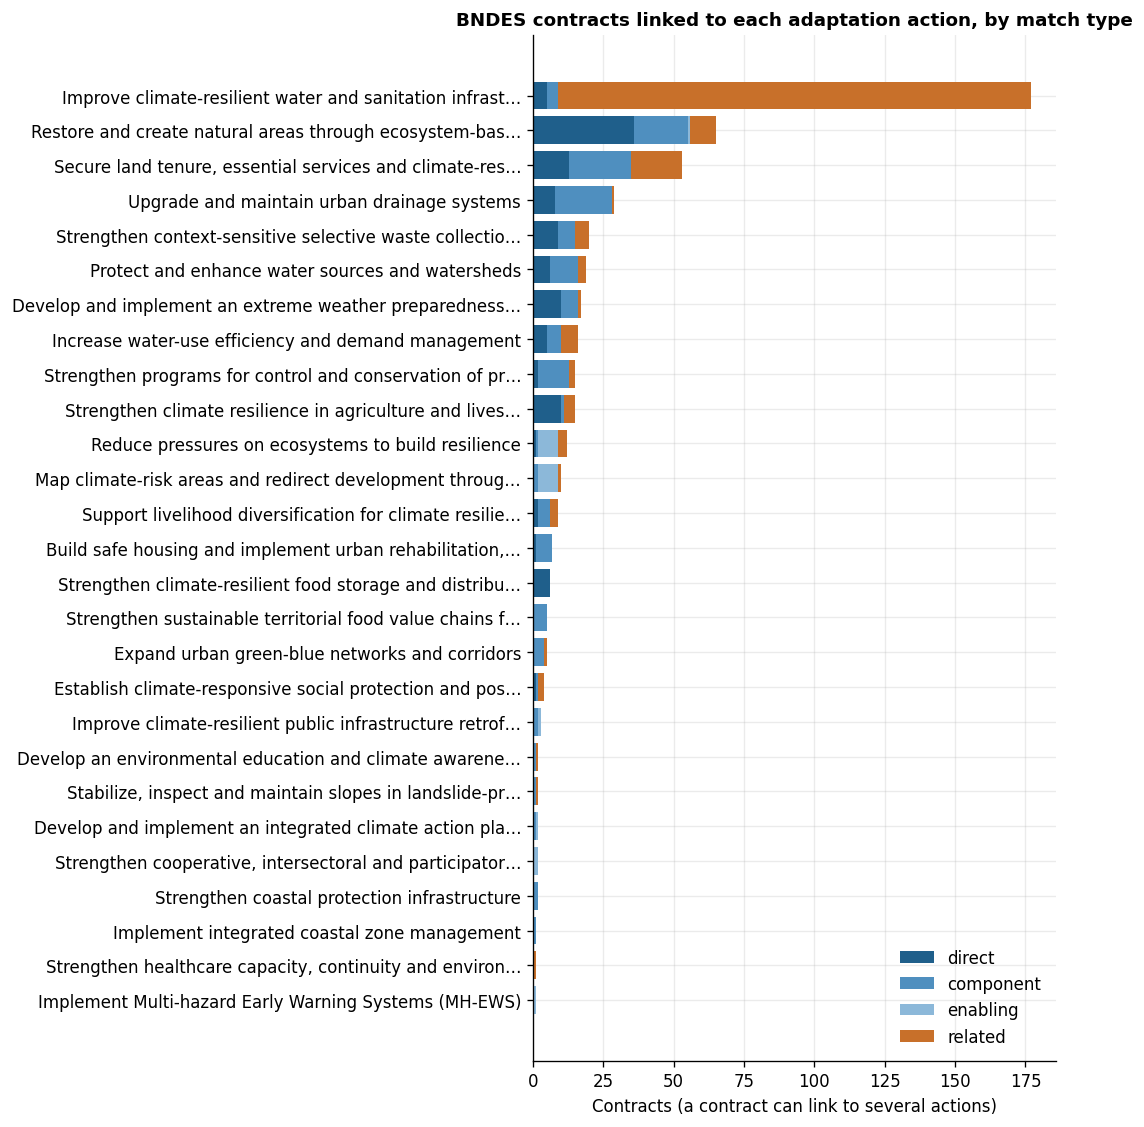

In [7]:
# 4.1 Contracts linked per action, by match type (all confidence levels)
plot = target_cov[target_cov["total"] > 0].sort_values("total")
labels = [n if len(n) <= 55 else n[:54].rstrip() + "…" for n in plot["action_name"]]
fig, ax = plt.subplots(figsize=(9, 0.3 * len(plot) + 1.4))
left = np.zeros(len(plot))
for m, color in MATCH_COLORS.items():
    ax.barh(labels, plot[m], left=left, color=color, label=m); left += plot[m].values
ax.set_title("BNDES contracts linked to each adaptation action, by match type"); ax.set_xlabel("Contracts (a contract can link to several actions)")
ax.legend(frameon=False, loc="lower right"); fig.tight_layout(); plt.show()

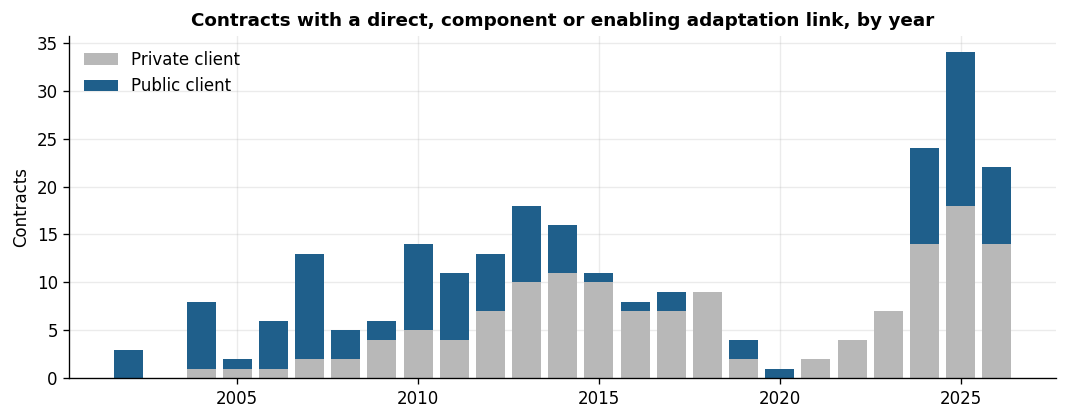

In [8]:
# 4.2 When adaptation-linked contracts were signed, public vs private client (direct/component/enabling only)
core = contract_links[contract_links["match_type"].isin(["direct", "component", "enabling"])].drop_duplicates("contract_number")
by_year = core.pivot_table(index="contract_year", columns="is_public_client", values="contract_number", aggfunc="nunique", fill_value=0)
by_year = by_year.reindex(range(subcredits["contract_year"].min(), subcredits["contract_year"].max() + 1), fill_value=0)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(by_year.index, by_year.get(False, 0), color="#b8b8b8", label="Private client")
ax.bar(by_year.index, by_year.get(True, 0), bottom=by_year.get(False, 0), color="#1f5f8b", label="Public client")
ax.set_title("Contracts with a direct, component or enabling adaptation link, by year"); ax.set_ylabel("Contracts")
ax.legend(frameon=False); fig.tight_layout(); plt.show()

## 5. Judgment clusters for adjudication

Medium-confidence links are drafts. Following the mapping method, they are grouped into recurring patterns (action × match type × weak-signal flag) so each pattern is decided once, with two example descriptions per cluster. Weak-signal rows were drafted at low confidence and are the first candidates to drop.

In [9]:
pending = crosswalk[crosswalk["adjudication_status"].eq("pending")]
clusters = (pending.groupby(["action_name", "match_type", "is_weak_signal"])
    .agg(descriptions=("src_description_pt", "nunique"),
         example_1=("src_description_en", lambda s: s.iloc[0][:140]),
         example_2=("src_description_en", lambda s: s.iloc[1][:140] if len(s) > 1 else ""))
    .sort_values("descriptions", ascending=False).reset_index())
print("pending links:", len(pending), "| clusters:", len(clusters))
clusters

pending links: 352 | clusters: 71


,action_name,match_type,is_weak_signal,descriptions,example_1,example_2
0,Improve climate-resilient water and sanitation infrastructure,related,True,131,"Operational and commercial development actions, plus expansion and improvement of the ...","Expansion of the water intake, treatment and distribution capacity in the municipality..."
1,"Secure land tenure, essential services and climate-resilient livelihoods for vulnerabl...",component,False,16,Expansion of access to water for food production on rural properties in the Brazilian ...,Support the implementation of sustainable agroecological production projects and nativ...
2,Restore and create natural areas through ecosystem-based measures,component,False,15,Support the conservation and sustainable management of babassu palm stands and the res...,Support the restoration of degraded areas and the strengthening of family farming in t...
3,Improve climate-resilient water and sanitation infrastructure,related,False,14,"Expansion of the infrastructure of the State of Paraiba, through investments in water ...","Execution of the second stage of the West Water Treatment Station (ETA Oeste), located..."
4,Upgrade and maintain urban drainage systems,component,False,12,Execution of the 2nd stage of the integrated urbanisation of the Ribeirao Pirapitinga ...,"Implementation of landfill cells, leachate ponds, and fencing, green-belt and stormwat..."
...,...,...,...,...,...,...
66,Reduce pressures on ecosystems to build resilience,direct,False,1,"Promote the adoption of management measures combined with fishing agreements, to reduc...",
67,Reduce pressures on ecosystems to build resilience,component,False,1,"To foster sustainable deforestation-reduction practices, with payment for environmenta...",
68,Protect and enhance water sources and watersheds,component,True,1,Support the strengthening of environmental management in the municipality of Cotriguac...,
69,Increase water-use efficiency and demand management,related,True,1,Development of a modular biotechnology system and a sludge biodigester for treating sw...,


## 6. Findings

The crosswalk covers all 6,594 distinct descriptions. 3,158 contained an adaptation-related term and were each judged against the 37 actions; the rest were screened out as `none` without individual review. 403 descriptions link to at least one action, which reaches 450 of 8,388 contracts (500 contract–action links). Only 104 contracts carry a high-confidence link; the other links are drafts awaiting adjudication.

Coverage is concentrated. Water and sanitation infrastructure has the most links (177 contracts), but 168 of them are `related`, and 131 descriptions in that group are weak signals: ordinary water or sewerage expansion with no drought or water-security framing. Nature-based restoration (65 contracts, 36 direct), rural and traditional communities (53) and urban drainage (29, of which 25 have public clients) are the substantive clusters. Twenty-seven actions are reached; 13 through a high-confidence direct or component link.

Ten actions have no BNDES precedent in this resource: climate-resilient building codes, hydrometeorological forecasting, telemetry monitoring, crop insurance, urban afforestation plans, urban agriculture, shelters, epidemiological data, urban cooling and shading, and climate mobility. Early warning, slopes, coastal protection and health each have one or two. Most of these are plans, regulations, systems or services rather than capital works, which is consistent with a development bank financing investment rather than evidence that they cannot be financed.

The decisive adjudication is the first cluster: whether generic sanitation expansion (131 descriptions) counts as `related` evidence for climate-resilient water and sanitation. Dropping it removes most of that action's links and leaves the high-confidence core almost unchanged.

Adjudication record: pending. When the medium clusters are decided, record the reviewer, the date and each cluster decision here, set `adjudication_status` to `accepted` or `rejected` in the crosswalk, and re-run.